# 02 - Joint reconstruction

One `ObjectMultiplexed` with two channels and a shared probe, so the atomic structure, the probe and the aberrations are common to both states by construction. Run unregularised first, then with the differential priors.

**Inputs** `data/ideal_*`  
**Outputs** `results/02_ideal_dose_*.npz`

**Note** The unregularised pass is the control. Without it, any improvement over `01` could be the priors or the coupling, and the two cannot be separated afterwards.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import sys
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

NOTEBOOK_DIR = Path.cwd()
DATA_DIR = NOTEBOOK_DIR / "data"
RESULTS_DIR = NOTEBOOK_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# method_wrappers and friends live one level up, in scripts/
sys.path.insert(0, str(NOTEBOOK_DIR.parent))
import method_wrappers
from quantem.core import config

config.set_device(0)

# Metadata is JSON; only the truth images and the datacubes are binary.
with open(DATA_DIR / "ideal_geometry.json") as handle:
    META = json.load(handle)
truth = np.load(DATA_DIR / "ideal_truth.npz")
delta_phi_true = truth["delta_phi_true"]

scan_params = META["scan"]["scan_params_for_method_wrappers"]
scan_step_ang = META["scan"]["step_ang"]
n_scan = META["scan"]["n_positions_per_side"]
object_dx_ang = META["cell"]["dx_ang"]
blob_centre_ang = np.array(META["object"]["blob_centre_ang"])
probe_r90_ang = META["probe"]["r90_ang"]

# derived in two lines rather than stored (see mask_rule / positions_rule in the JSON)
ii, jj = np.indices((n_scan, n_scan))
scan_mask = ((ii + jj) % 2 == 0).astype(np.uint8)
scan_axis = (np.arange(n_scan) - (n_scan - 1) / 2) * scan_step_ang
object_x_ang = (np.arange(META["cell"]["n_pixels"]) - META["cell"]["n_pixels"] // 2) * object_dx_ang

print(f"scan        : {n_scan}^2 at {scan_step_ang} A over {META['scan']['extent_ang']} A")
print(f"scan params : {scan_params}")
print(f"probe r90   : {probe_r90_ang} A")
print(f"truth       : peak |delta phi| = {np.abs(delta_phi_true).max():.5f} rad")


def load_merged(dose_key):
    return np.load(DATA_DIR / f"ideal_merged_dose_{dose_key}.npy")


def show_delta(result, title, truth=delta_phi_true):
    """One method's delta phi beside the ground truth, on a shared symmetric scale."""
    recovered = result["delta_phi"]
    vmax = float(np.abs(truth).max())
    fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.2), constrained_layout=True)
    im = axes[0].imshow(truth.T, origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    axes[0].set_title(r"ground truth $\Delta\varphi$")
    fig.colorbar(im, ax=axes[0], shrink=0.8, label="rad")
    rv = float(np.abs(recovered).max())
    im = axes[1].imshow(recovered.T, origin="lower", cmap="RdBu_r", vmin=-rv, vmax=rv)
    axes[1].set_title(f"{title}\npeak {rv:.5f} rad")
    fig.colorbar(im, ax=axes[1], shrink=0.8, label="rad")
    for ax in axes:
        ax.set_xticks([]); ax.set_yticks([])
    plt.show()


def save_result(index, dose_key, result, **extra):
    """Arrays to .npz, every scalar to a sibling .json so the run is readable."""
    path = RESULTS_DIR / f"{index}_dose_{dose_key}.npz"
    payload = {k: v for k, v in result.items() if isinstance(v, np.ndarray) or v is None}
    payload = {k: (np.array([]) if v is None else v) for k, v in payload.items()}
    # 09 has to put every method on a common physical grid and they do not share one:
    # the iterative methods reconstruct at lambda/(2*theta_max) ~ 0.19 A while SSB lands
    # on the scan grid. Record the pixel size rather than let 09 guess it.
    # The wrapper reports its own pixel size. Reading it off the ptycho object here
    # was wrong for SSB: DirectPtychography has both `sampling` (the detector-side
    # real-space pixel) and `scan_sampling` (the grid the SSB object actually lives
    # on), and picking by attribute order silently took the wrong one.
    if result.get("pixel_size_ang") is not None:
        extra["pixel_size_ang"] = np.asarray(result["pixel_size_ang"], dtype=float)
    np.savez_compressed(path, **payload, **extra)
    side = {k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in extra.items()}
    side.update(method=index, dose=dose_key,
                delta_phi_shape=list(np.shape(payload["delta_phi"])),
                delta_phi_peak_rad=float(np.abs(payload["delta_phi"]).max()))
    with open(path.with_suffix(".json"), "w") as handle:
        json.dump(side, handle, indent=2)
    print("wrote", path.name, "+", path.with_suffix(".json").name)
    return path

cuda:0
scan        : 182^2 at 0.1641 A over 30.0 A
scan params : {'probe_energy': 300000.0, 'probe_semiangle': 30.0, 'probe_defocus': 100.0, 'scan_step': 0.3282}
probe r90   : 3.0248 A
truth       : peak |delta phi| = 0.02106 rad


## Parameters

The method's own knobs. The geometry comes from `00` and is not restated here.

In [2]:
DOSE_KEYS = ["inf", "1e6", "1e5"]   # trim this while iterating

# Calibrated, not guessed: obj_lr swept over {1e-3, 1e-2, 1e-1, 5e-1} for 40 iterations
# on pari/inf. 1e-3 reached the lowest final loss (0.4276 vs 0.4475-0.4552) and was within
# 2% of it by iteration 4; the larger rates were still descending at 40. 0.49 s/iteration.
# Raised 25 -> 60: the sweep above was a single-channel object, and this one fits two
# channels plus a shared probe, so it is given more room rather than assumed equal.
NUM_ITERS = 60
OBJ_LR = 1e-3
PROBE_LR = 1e-4
BATCH_SIZE = 128

# pass 1: coupling only, no differential priors
UNREG = dict(tv_weight=0.0, tv_channel_diff=0.0)
# pass 2: the priors from the proposal -- smoothness of the lattice, and of delta phi
REG = dict(tv_weight=1.0, tv_channel_diff=10.0)

## Run


=== unreg, dose inf ===


Forcing best fit rotation to 0 degrees.
Forcing transpose of intensities to False.


Normalizing intensities:   0%|          | 0/33124 [00:00<?, ?probe position/s]

/home/rotem/ptycho_light/quantem/src/quantem/diffractive_imaging/object_models.py:1305: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Copy.cpp:308.)
  post_constraint_obj[ch] = self.apply_hard_constraints(


  0%|          | 0/60 [00:00<?, ?it/s]

  137 s


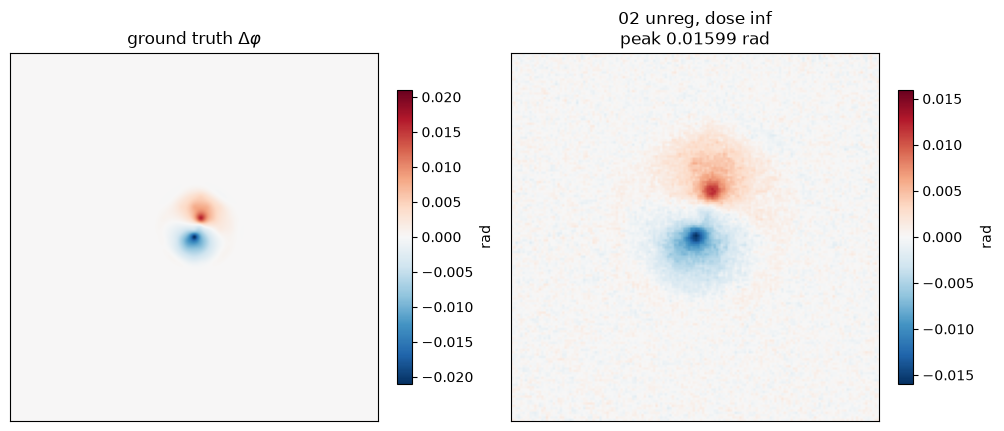

wrote 02_unreg_dose_inf.npz + 02_unreg_dose_inf.json

=== unreg, dose 1e6 ===


Forcing best fit rotation to 0 degrees.
Forcing transpose of intensities to False.


Normalizing intensities:   0%|          | 0/33124 [00:00<?, ?probe position/s]

  0%|          | 0/60 [00:00<?, ?it/s]

  136 s


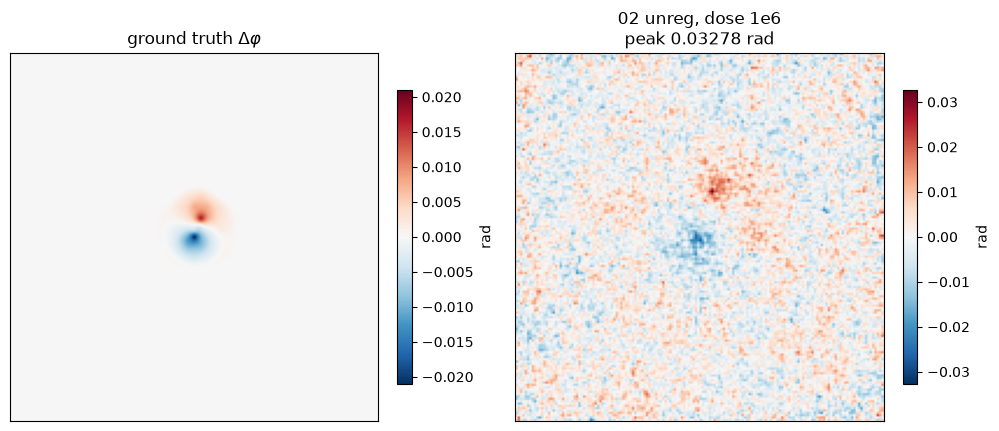

wrote 02_unreg_dose_1e6.npz + 02_unreg_dose_1e6.json

=== unreg, dose 1e5 ===


Forcing best fit rotation to 0 degrees.
Forcing transpose of intensities to False.


Normalizing intensities:   0%|          | 0/33124 [00:00<?, ?probe position/s]

  0%|          | 0/60 [00:00<?, ?it/s]

  138 s


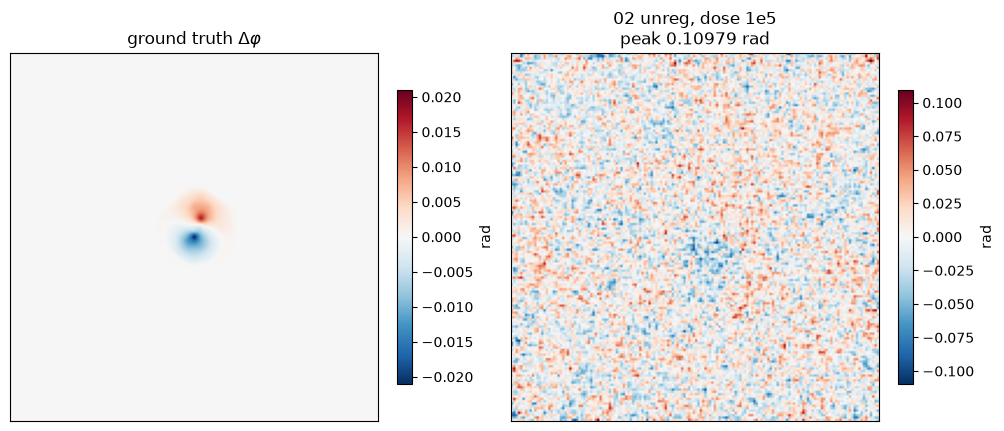

wrote 02_unreg_dose_1e5.npz + 02_unreg_dose_1e5.json

=== reg, dose inf ===


Forcing best fit rotation to 0 degrees.
Forcing transpose of intensities to False.


Normalizing intensities:   0%|          | 0/33124 [00:00<?, ?probe position/s]

  0%|          | 0/60 [00:00<?, ?it/s]

/home/rotem/ptycho_light/quantem/src/quantem/diffractive_imaging/object_models.py:412: UserWarning: calculating TV loss for phase, need to check phase wrapping. Easiest fix is scalar phase array.
  warn(


  163 s


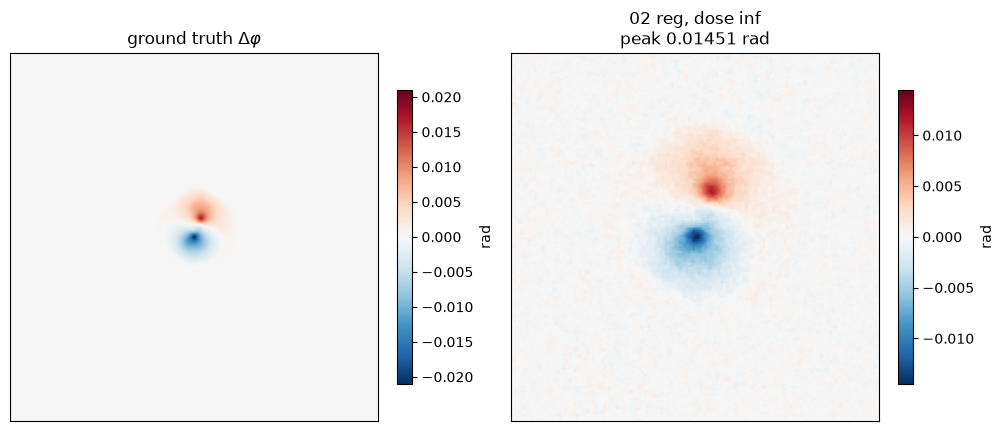

wrote 02_reg_dose_inf.npz + 02_reg_dose_inf.json

=== reg, dose 1e6 ===


Forcing best fit rotation to 0 degrees.
Forcing transpose of intensities to False.


Normalizing intensities:   0%|          | 0/33124 [00:00<?, ?probe position/s]

  0%|          | 0/60 [00:00<?, ?it/s]

  151 s


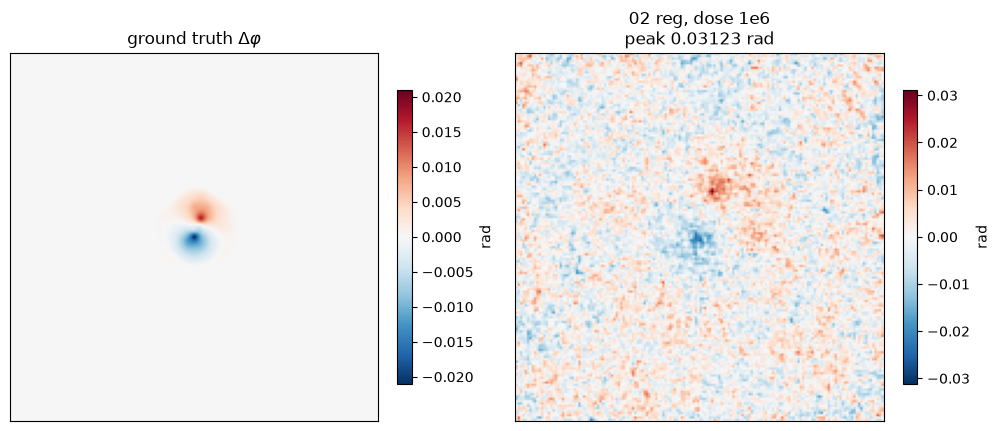

wrote 02_reg_dose_1e6.npz + 02_reg_dose_1e6.json

=== reg, dose 1e5 ===


Forcing best fit rotation to 0 degrees.
Forcing transpose of intensities to False.


Normalizing intensities:   0%|          | 0/33124 [00:00<?, ?probe position/s]

  0%|          | 0/60 [00:00<?, ?it/s]

  150 s


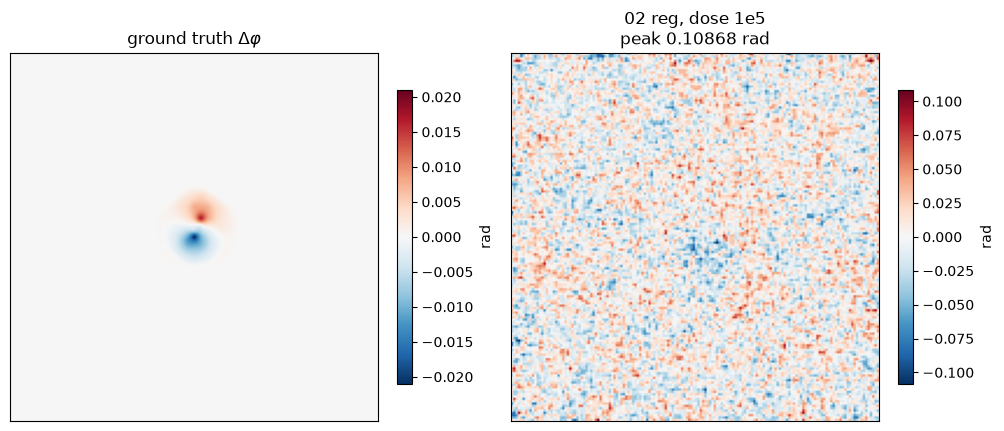

wrote 02_reg_dose_1e5.npz + 02_reg_dose_1e5.json


In [3]:
for label, knobs in (("unreg", UNREG), ("reg", REG)):
    for dose_key in DOSE_KEYS:
        print(f"\n=== {label}, dose {dose_key} ===")
        merged = load_merged(dose_key)
        t0 = time.time()
        res = method_wrappers.co_reconstruction_regularized(
            merged, scan_mask, scan_params,
            num_iters=NUM_ITERS, obj_lr=OBJ_LR, probe_lr=PROBE_LR,
            batch_size=BATCH_SIZE, **knobs,
        )
        print(f"  {time.time()-t0:.0f} s")
        show_delta(res, f"02 {label}, dose {dose_key}")
        save_result(f"02_{label}", dose_key, res)
        del merged, res
        torch.cuda.empty_cache()